# SciPy: Finding a Weak NMR Signal in Noise

Mohammed Alhazmi

**CSCI 3656**  Software Presentation November 2026
**Software: [SciPy](https://scipy.org/)**.
**Main Question:** Can numerical signal processing help us recover a NMR signal that is hard to see on the scope?

**Importent:** The signals here are simulated, not the actual measruemnts from my experiment, but I want to use the same tools on my real data later.

## What is SciPy?

it's an open soruce python library for scientifc computing. it give practical algoritms for numerical integration, differntial equation and optimization. its public and developed by a commuunity of contributors.

For my EFNMR I'm most intested in:

| SciPy module | What I can do with it |
| :--- | :--- |
| `scipy.signal` | Build filters to reduce unwanted frequencies |
| `scipy.fft` | Find frequencies hidden inside a measured time signal |
| `scipy.optimize` | Eventually fit a decaying sinusoid to estimate its frequency and decay time |

The reason why I select it is because buidling an NMR we are trying to detect a physical signal that SciPy would analyze and digitzed aftrward

## The Physics connection

We have a hydrogen nucleus precesses in a magnetic filed and we know at its **Larmor Frequency** we have:

$$f_L = \frac{\gamma}{2\pi} B$$

For protons $\frac{\gamma}{2\pi} \approx 42.58MHz$ so an Earth strenght magentic field near $50\mu T$ we suggest that a frequency near $2.13kHz$. Actual filed strength and resonace frequncey depends on the locaiton and setup.

After we polirize the idealized NMR picup signal can look like a decaying *sinusoid*:

$$$s(t) = Ae^{-t/T*_2} sin(2\pi f_Lt+\phi)$$

in real world scienro the measured signal will contain noise, interferance and electornic artifcats. The code below simulute a plausible **signal shape**. it's not a calibrated predicaiton of the project signal strength.

SciPy version: 1.14.1


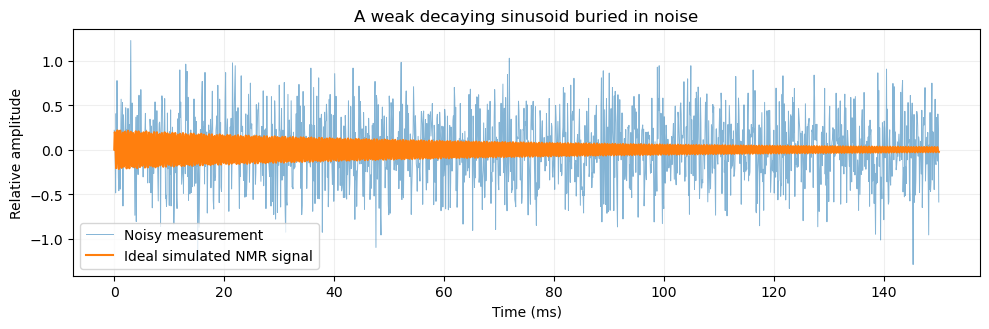

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, fft
import scipy

# This is just for the sake of knwoing what version I'm using since 
# I have multipe notebooks that have diff. instaliations
print('SciPy version:', scipy.__version__)

fs = 12_000           # sample rate, samples/second
seconds = 0.15
t = np.arange(0, seconds, 1/fs)
f_true = 2_100        # Hz: chosen demonstration frequency
T2star = 0.075       # seconds: simulated decay time
rng = np.random.default_rng(3656)

clean = 0.22 * np.exp(-t / T2star) * np.sin(2*np.pi*f_true*t)
noise = 0.35 * rng.normal(size=t.size)
interference = (0.18*np.sin(2*np.pi*700*t) +
                0.13*np.sin(2*np.pi*3_400*t))
measured = clean + noise + interference

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t*1_000, measured, lw=0.7, alpha=0.55, label='Noisy measurement')
ax.plot(t*1_000, clean, lw=1.5, label='Ideal simulated NMR signal')
ax.set(xlabel='Time (ms)', ylabel='Relative amplitude',
       title='A weak decaying sinusoid buried in noise')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

What we see is the **Blue Noise** trace makes the weak decay diffcult to indetify by an eye. And a Scope recording will have the same issue.

## Finding the frequencey with a Fourier Transform

We can use the **Fast Fourier Trasnform** (FFT) that covnerts a time domain waveform into a frequency spectrum. Here I used a [Hann window](https://en.wikipedia.org/wiki/Hann_function) this will reduce the spectural leakage and then look for strong peaks. The largest peak in a *restricted frequency* region is our simple esitamte of the resonace. But this assume that we know where the resonace should be 

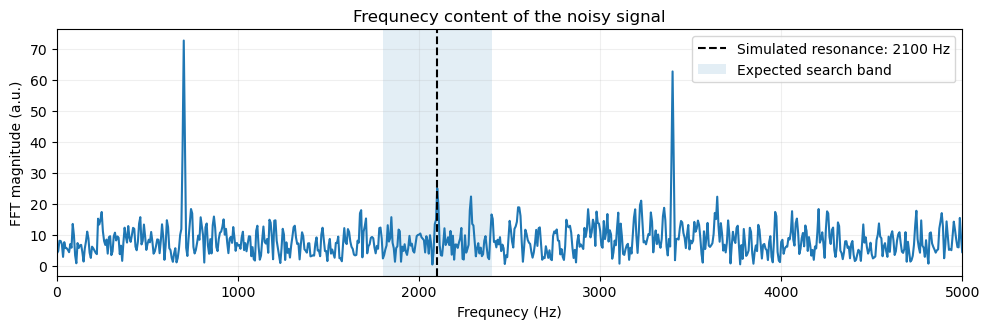

FFT estimate within search band: 2100.0 Hz


In [7]:
def amplitude_spectrum(x):
    window = signal.windows.hann(len(x), sym=False)
    spectrum = np.abs(fft.rfft(x * window))
    freqs = fft.rfftfreq(len(x), 1/fs)
    return freqs, spectrum

freqs, amplitude = amplitude_spectrum(measured)
region = (freqs >= 1_800) & (freqs <= 2_400)
raw_estimate = freqs[region][np.argmax(amplitude[region])]

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(freqs, amplitude)
ax.axvline(f_true, ls='--', color='black', label=f'Simulated resonance: {f_true} Hz')
ax.axvspan(1_800, 2_400, alpha=0.12, label='Expected search band')
ax.set(xlim=(0, 5_000), xlabel='Frequnecy (Hz)', ylabel='FFT magnitude (a.u.)',
       title='Frequnecy content of the noisy signal')
ax.grid(alpha=0.2); ax.legend(); plt.tight_layout(); plt.show()
print(f'FFT estimate within search band: {raw_estimate:.1f} Hz')

**Interpretaion**: The spectrum can reveal whihc frequncey is present even if the orignal trace is messy. But we need to be carful here a **A peak does not prove it came from NMR; interfrence can produce peaks too**

## Apply a Scipy Band-pass Filter

A **Band-pass** filter keep the selected range of frequencies and suppresses frequencies outside of that range. we can use **[Butterworth](https://en.wikipedia.org/wiki/Butterworth_filter) filter** with second order section for numerical stability.

`scipy.sosfiltfilt` it filter the forawrd and backward, its more used on offline analysis because it avoids the net phase delay but is not for real time filter for that I'm thinking og using `scipy.sosfilt` instead.

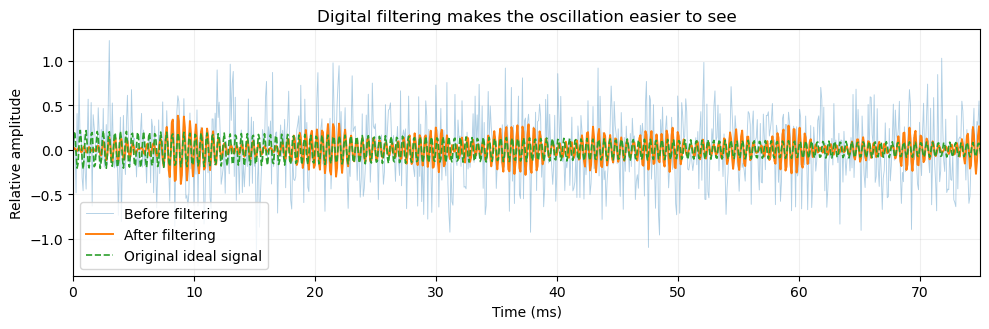

Filtered FFT peak: 2100.0 Hz
True simulated resonance: 2100.0 Hz


In [8]:
low_hz, high_hz = 1_800, 2_400
sos = signal.butter(4, (low_hz, high_hz), btype='bandpass',
                    fs=fs, output='sos')
filtered = signal.sosfiltfilt(sos, measured)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t*1_000, measured, lw=0.65, alpha=0.35, label='Before filtering')
ax.plot(t*1_000, filtered, lw=1.4, label='After filtering')
ax.plot(t*1_000, clean, lw=1.2, ls='--', label='Original ideal signal')
ax.set(xlim=(0, 75), xlabel='Time (ms)', ylabel='Relative amplitude',
       title='Digital filtering makes the oscillation easier to see')
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

f_filtered, amp_filtered = amplitude_spectrum(filtered)
filtered_estimate = f_filtered[region][np.argmax(amp_filtered[region])]
print(f'Filtered FFT peak: {filtered_estimate:.1f} Hz')
print(f'True simulated resonance: {f_true:.1f} Hz')

But we still need to be carful because filtring can remove part of the singal we want or even give use an edge artifacs. the visual improvemnts we see does not mean that our estiamte is more accurate.

## Proposed Group Project: Numerical Accuracy and Efficency in SciPy

For the group project I'm thinking to widen my project since not all of my peers are intersted in Physics. So we can invesitate how idfferent numerical algoritms in SciPy perform when prepccessing signals. We could use audio, simulated data, and sensor measremtns to make the projet more abraod.

We could comapre alogrithms that based on numerical accuracy, stablity and computaional efficeiny. For example we could compare FFT with a [Direct Discreate Fourier Trasnform](https://en.wikipedia.org/wiki/Discrete_Fourier_transform) (DFT).

We also could look how diff. filter alogrtims perform undervarying noise levels.

## Question I want to Investigate

How can I choose a filter that remove noise without distorting the frequncy, amplitude or decay time of an extrremelyt weak signal?